# Generative Adversarial Network to generate steel samples 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from keras.layers import Dense
from keras.layers import Dropout
from keras.models import Sequential
from keras.src.optimizers import Adam
import xgboost as xgb


<br>

## 1. Load and prepare data

In [2]:
# Read labeled_OES_data_2.csv
data = pd.read_csv("labeled_OES_data_2.csv")

# convert steel types to numbers
# Note: in our project steel types are not predefined, but will be extracted from the supplied file of data
classes_dict = {"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
data["steel_class"] = [classes_dict[c] for c in data["steel_class"] ]

# make data numeric
for column in data.columns:
        for index, value in data[column].items():
            if isinstance(value, str):
                data.at[index, column] = value.replace(",", ".")
data = data.map(pd.to_numeric)
data.head()

,C,Si,Mn,P,S,Cr,Ni,Al,Cu,steel_class
0,0.104,0.806,0.890,0.031,0.044,0.013,0.047,0.006,0.168,2
1,0.262,0.219,0.525,0.021,0.040,0.035,0.051,0.002,0.145,0
2,0.235,0.239,0.729,0.028,0.042,0.015,0.050,0.004,0.167,0
3,0.116,0.848,0.737,0.023,0.038,0.053,0.070,0.006,0.172,2
4,0.195,0.321,0.570,0.033,0.057,0.023,0.075,0.007,0.281,0


## 2. Group dataset by steel types

In [3]:
element_data_grouped_by_steeltype = data.groupby("steel_class")
dfs_by_steeltype = {}

for type, group_data in element_data_grouped_by_steeltype:
    dfs_by_steeltype[type] = group_data.iloc[:, :-1]

for type in dfs_by_steeltype.keys():
    print(f"\nSteel Type {type}:")
    print(dfs_by_steeltype[type].head())


Steel Type 0:
       C     Si     Mn      P      S     Cr     Ni     Al     Cu
1  0.262  0.219  0.525  0.021  0.040  0.035  0.051  0.002  0.145
2  0.235  0.239  0.729  0.028  0.042  0.015  0.050  0.004  0.167
4  0.195  0.321  0.570  0.033  0.057  0.023  0.075  0.007  0.281
5  0.130  0.438  0.691  0.020  0.037  0.020  0.044  0.004  0.437
7  0.284  0.233  0.635  0.022  0.042  0.009  0.050  0.003  0.175

Steel Type 1:
        C     Si     Mn      P      S     Cr     Ni     Al     Cu
12  0.076  0.005  0.402  0.017  0.018  0.044  0.036  0.002  0.091
17  0.070  0.005  0.428  0.008  0.018  0.005  0.027  0.002  0.098
33  0.069  0.005  0.392  0.020  0.028  0.008  0.035  0.002  0.122
36  0.058  0.005  0.393  0.029  0.030  0.022  0.052  0.002  0.172
37  0.061  0.005  0.312  0.020  0.035  0.025  0.047  0.002  0.147

Steel Type 2:
        C     Si     Mn      P      S     Cr     Ni     Al     Cu
0   0.104  0.806  0.890  0.031  0.044  0.013  0.047  0.006  0.168
3   0.116  0.848  0.737  0.023  0.038

### Visualize distribution

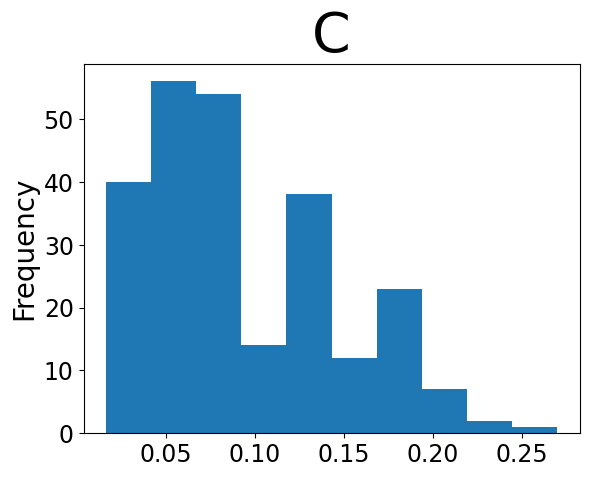

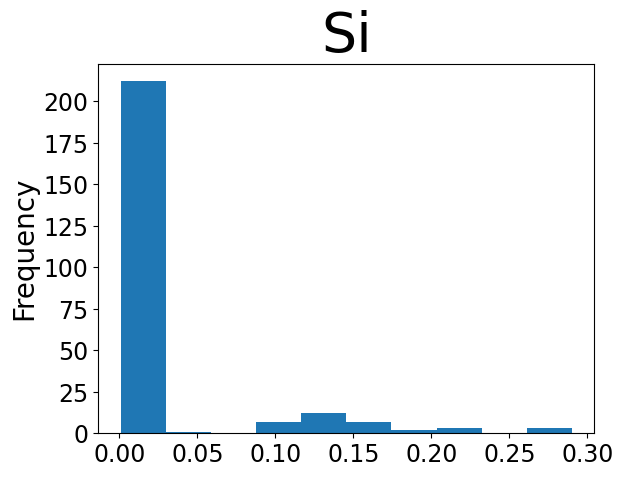

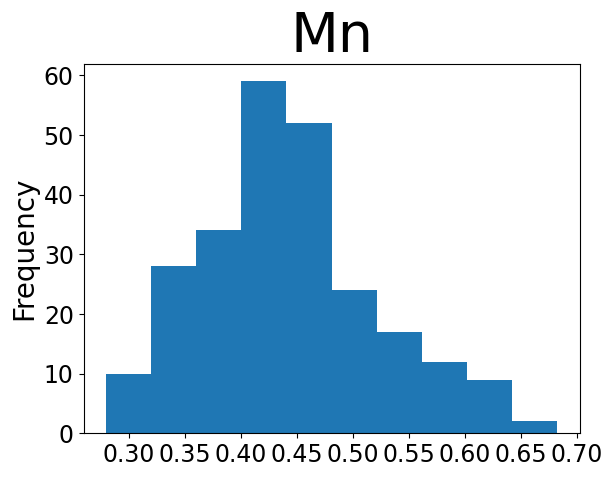

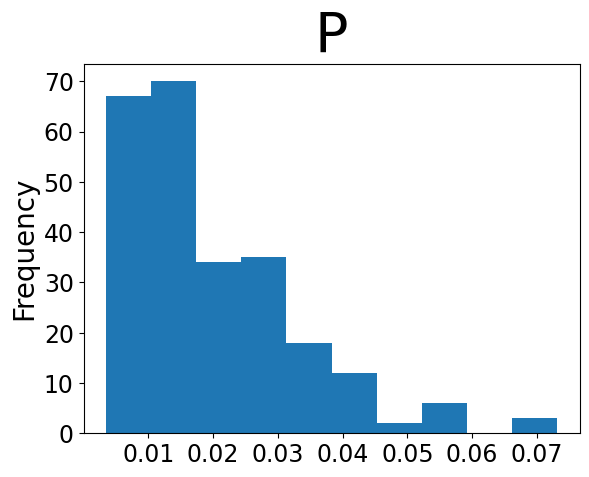

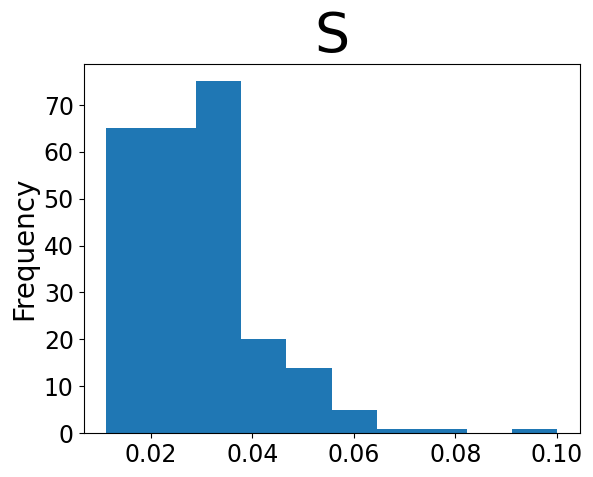

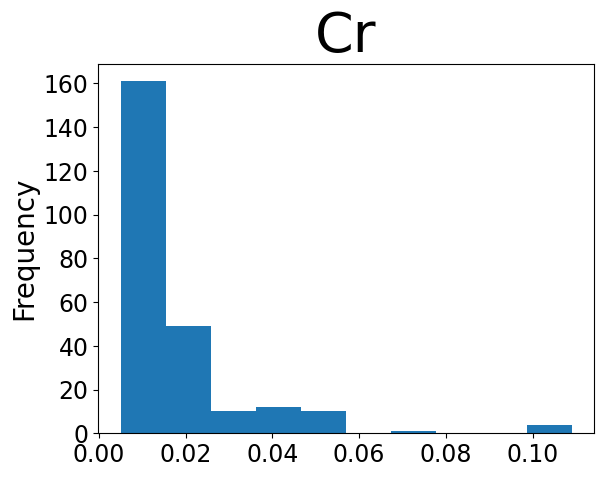

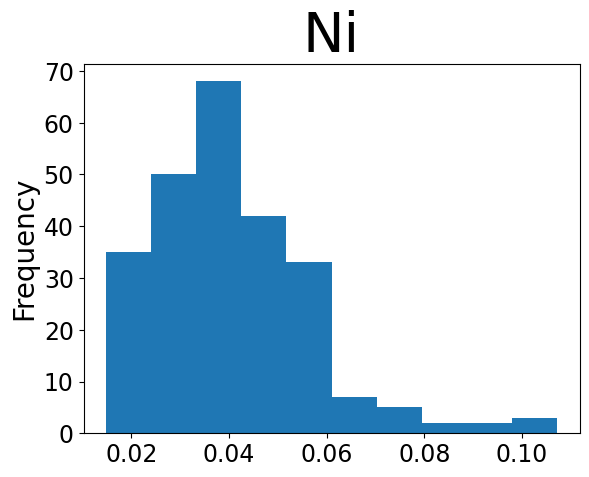

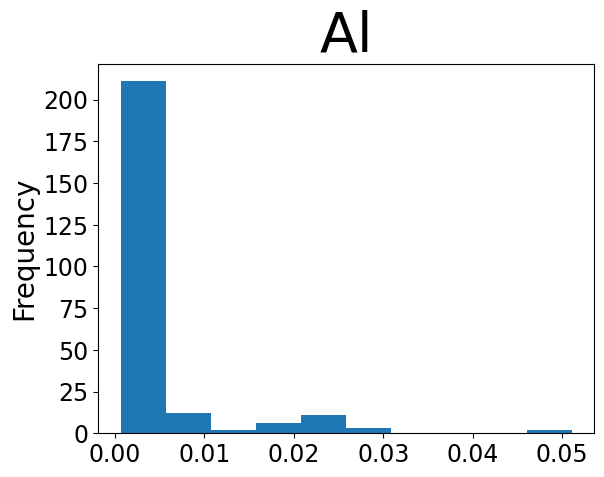

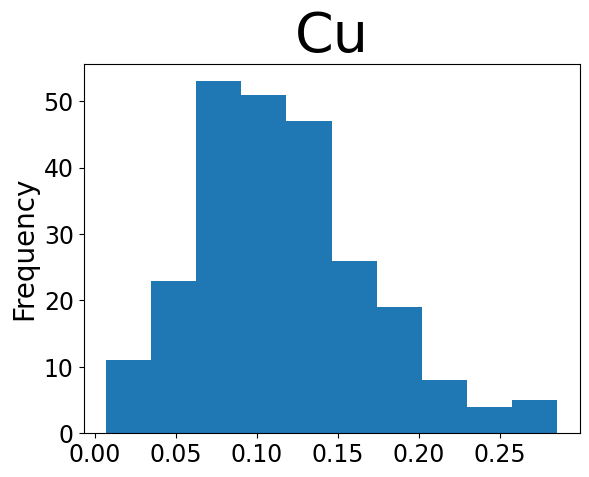

In [4]:
for col in dfs_by_steeltype[1].columns:  # Loop through columns (excluding the first)
    dfs_by_steeltype[1][col].plot.hist()
    plt.title(col, fontsize=40)  # Set title as element name
    plt.ylabel("Frequency", fontsize=20)
    plt.xticks(fontsize=17)  # Adjust x-axis tick label font size
    plt.yticks(fontsize=17)
    #plt.savefig(f"Distribution_{col}.png", format='png')
    plt.show()
    plt.close()


<br>

## 3. Create construct for GAN

In [5]:
# latent space is random noise out of which the data will be formed
def build_generator(latent_space):
    generator = Sequential()
    generator.add(Dense(10, input_dim=latent_space, activation="relu"))
    generator.add(Dense(128, activation="relu"))
    generator.add(Dropout(0.3))
    generator.add(Dense(128, activation="relu"))
    generator.add(Dense(9, activation="sigmoid"))
    return generator

In [6]:
def build_discriminator():
    discriminator = Sequential()
    discriminator.add(Dense(10, input_dim = 9, activation="relu"))
    discriminator.add(Dense(128, activation="relu"))
    discriminator.add(Dropout(0.3))
    discriminator.add(Dense(128, activation="relu"))
    discriminator.add(Dense(1, activation="sigmoid"))
    return discriminator

In [7]:
def build_gan(generator, discriminator):
    discriminator.trainable = False
    gan = Sequential()
    gan.add(generator)
    gan.add(discriminator)
    return gan

<br>

## 4. Create Generator, Discriminator and GAN

In [8]:
latent_space = 10
optimizer_dis = Adam(learning_rate=3e-4)
optimizer_gan = Adam(learning_rate=3e-4)

In [9]:
discriminator_St37 = build_discriminator()
discriminator_St37.compile(optimizer=optimizer_dis, loss="binary_crossentropy")

generator_St37 = build_generator(latent_space)
generator_St37.summary()

gan_St37 = build_gan(generator_St37, discriminator_St37)
gan_St37.compile(optimizer=optimizer_gan, loss="binary_crossentropy")


C:\Users\jonat\PycharmProjects\GAN_BA\venv\lib\site-packages\keras\src\layers\core\dense.py:86: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,191 (74.96 KB)

 Trainable params: 19,191 (74.96 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
#discriminator_St37.summary()

<br>

## 5. Train the GAN

In [11]:
epochs = 1000
batch_size = 64

X_train_St37 = dfs_by_steeltype[1]

misclassified_St37_arrays = [
[0.108 , 0.0097, 0.565 , 0.0254, 0.0262, 0.0214, 0.0431, 0.002 , 0.121 ],
[0.0918, 0.005 , 0.296 , 0.0245, 0.0176, 0.0104, 0.0337, 0.002 , 0.242 ],
[0.104 , 0.005 , 0.318 , 0.0271, 0.0252, 0.0118, 0.0322, 0.0045, 0.261 ],
[0.108000,  0.009700,  0.565000,  0.025400,  0.026200,  0.021400,  0.043100,   0.002000,  0.121000],
[0.148667,  0.005533,  0.552167,  0.031317,  0.031917,  0.030283,  0.039033,   0.002000,  0.119000],
[0.091800,  0.005000,  0.296000,  0.024500,  0.017600,  0.010400,  0.033700,   0.002000,  0.242000],
[0.104000,  0.005000,  0.318000,  0.027100,  0.025200,  0.011800,  0.032200,   0.004500,  0.261000]]




misclassified_St37_df = pd.DataFrame(misclassified_St37_arrays)
misclassified_St37_df.columns = ["C", "Si", "Mn", "P", "S", "Cr", "Ni", "Al", "Cu" ]

for i in range(7):
    X_train_St37 = pd.concat([X_train_St37, misclassified_St37_df], ignore_index=True)


In [12]:
dis_real_hist = []
dis_fake_hist = []
gen_hist = []
for epoch in range(epochs):
    # get batch_size number of random samples out of training data
    real_samples = X_train_St37.values[np.random.randint(0, X_train_St37.shape[0], batch_size)]

    # get batch_size number of fake samples
    # to speed up computation we chose latent_space = 10
    lat_noise = np.random.normal(0, 1, (batch_size, latent_space))
    fakes = generator_St37.predict(lat_noise)

    discriminator_St37.trainable = True
    dis37_loss_real = discriminator_St37.train_on_batch(real_samples, np.ones((batch_size, 1)))
    dis37_loss_fake = discriminator_St37.train_on_batch(fakes, np.zeros((batch_size, 1)))

    lat_noise = np.random.normal(0, 1, (batch_size, latent_space))
    g37_loss = gan_St37.train_on_batch(lat_noise, np.ones((batch_size, 1)))
    print("Epoch", epoch + 1, ": ", "dis37_loss_fake:", dis37_loss_fake, ",", "dis37_loss_real:", dis37_loss_real, ", ", "gen_loss: ",  g37_loss)
    dis_real_hist.append(dis37_loss_real)
    dis_fake_hist.append(dis37_loss_fake)
    gen_hist.append(g37_loss)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step  
Epoch 1 :  dis37_loss_fake: 0.6869291 , dis37_loss_real: 0.68230885 ,  gen_loss:  0.7028812
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step  
Epoch 2 :  dis37_loss_fake: 0.6862933 , dis37_loss_real: 0.68267864 ,  gen_loss:  0.69979894
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step  
Epoch 3 :  dis37_loss_fake: 0.6856138 , dis37_loss_real: 0.68351096 ,  gen_loss:  0.69747657
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
Epoch 4 :  dis37_loss_fake: 0.68495023 , dis37_loss_real: 0.6829639 ,  gen_loss:  0.69475806
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step  
Epoch 5 :  dis37_loss_fake: 0.68506944 , dis37_loss_real: 0.6828289 ,  gen_loss:  0.6930453
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Epoch 6 :  dis37_loss_fake: 0.68519306 , dis37_loss_real: 0.68287796 ,  gen_loss:  0.6925934
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step  
Epoch 7 :  dis37_loss_fake: 0.6851336 , dis37_loss_real: 0.68308854 ,  gen_loss:  0.6908983
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step  
Epoch 8 :  dis37_loss_fake: 0.6847792 , dis37_lo

In [2]:
plt.plot(dis_real_hist, label='discriminator real loss')
plt.plot(dis_fake_hist, label='discriminator fake loss')
plt.plot(gen_hist, label='gen loss')
plt.legend()
plt.savefig('GAN_loss_fig.png')
plt.show()

NameError: name 'plt' is not defined

In [14]:
# Save the generator model
generator_St37.save("generator_St37_1000Epochs.keras")

# Save the discriminator model
#discriminator_St37.save("discriminator_St37_1000Epochs.keras")


<br>

## 6. Augment new data with the generator

<br>

In [15]:
#load models
#generator_St37 = keras.models.load_model("GAN_generator_St37_1000Epochs.keras", safe_mode=False)
#discriminator_St37 = keras.models.load_model("discriminator_St37_1000Epochs.keras")

In [16]:
lat_noise = np.random.normal(0, 1, (100, latent_space))
augmented_data_St37 = generator_St37.predict(lat_noise)

augmented_data_St37

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


array([[6.75333198e-03, 2.63631635e-04, 3.69979948e-01, 1.93555781e-03,
        1.63537625e-05, 1.24915414e-05, 1.03452512e-04, 3.02424218e-04,
        2.07914338e-01],
       [6.03949931e-03, 1.65123405e-04, 3.45682055e-01, 1.25392014e-03,
        6.56057728e-06, 5.34031960e-06, 8.15825624e-05, 1.79699753e-04,
        1.84379086e-01],
       [2.25243084e-02, 1.84957276e-03, 3.73156428e-01, 6.00845274e-03,
        2.12554296e-04, 1.57554925e-04, 9.26319510e-04, 1.81223161e-03,
        2.22893849e-01],
       [1.92364235e-03, 3.21960797e-05, 3.45656723e-01, 3.52531904e-04,
        1.09350026e-06, 5.03954652e-07, 9.01288604e-06, 4.93856605e-05,
        1.72140524e-01],
       [9.13367793e-03, 3.62402468e-04, 3.64471763e-01, 2.03943206e-03,
        1.56186234e-05, 1.21016465e-05, 1.55243877e-04, 3.61221784e-04,
        1.99785873e-01],
       [1.48223992e-02, 8.90873722e-04, 3.61297280e-01, 3.36674508e-03,
        8.73421013e-05, 7.49733081e-05, 3.99067183e-04, 8.41013039e-04,
        2.1

<br>

**Compare augmented data to real ones after PCA on a 3D coordinate system**

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from matplotlib.lines import Line2D

In [18]:
scaler = StandardScaler()
scaled_augmented_rows = scaler.fit_transform(augmented_data_St37)
scaled_augmented_rows

array([[-3.01077366e-01, -3.80640805e-01,  8.51620972e-01,
        -1.49398163e-01, -3.86143774e-01, -3.76596600e-01,
        -3.86433214e-01, -3.54911745e-01,  7.27171719e-01],
       [-3.90971571e-01, -5.09955585e-01, -4.65138555e-01,
        -4.35847729e-01, -4.76494193e-01, -4.58534300e-01,
        -4.37724262e-01, -5.11443853e-01,  4.30105627e-02],
       [ 1.68498933e+00,  1.70127308e+00,  1.02376187e+00,
         1.56218410e+00,  1.42397213e+00,  1.28551960e+00,
         1.54341567e+00,  1.57081115e+00,  1.16262066e+00],
       [-9.09288704e-01, -6.84453368e-01, -4.66511369e-01,
        -8.14644694e-01, -5.26932597e-01, -5.13948739e-01,
        -6.07920110e-01, -6.77656293e-01, -3.12759966e-01],
       [-1.31622318e-03, -2.50981271e-01,  5.53119600e-01,
        -1.05746336e-01, -3.92926037e-01, -3.81063938e-01,
        -2.64968276e-01, -2.79916853e-01,  4.90880251e-01],
       [ 7.15074480e-01,  4.42759275e-01,  3.81086946e-01,
         4.52040046e-01,  2.68783748e-01,  3.393108

In [19]:
pca = PCA(3)
pca_augmented_rows = pca.fit_transform(scaled_augmented_rows)
pca_augmented_rows 

array([[-3.39172930e-01, -1.34229231e+00,  7.26012886e-02],
       [-1.22968233e+00, -2.28556618e-01, -3.69199395e-01],
       [ 4.34962559e+00,  1.79744557e-01, -1.03586473e-01],
       [-1.85928416e+00, -9.36736763e-02, -8.86662379e-02],
       [-2.68204302e-01, -9.95474279e-01,  8.61119758e-03],
       [ 1.35733676e+00, -4.42748696e-01, -3.66490185e-01],
       [-1.31613135e+00,  4.49102148e-02,  8.27673525e-02],
       [-3.02320194e+00,  2.05297351e+00,  1.76786005e-01],
       [ 1.04517210e+00, -1.18167651e+00, -3.69885117e-01],
       [ 2.69427991e+00, -9.65276003e-01,  2.38186389e-01],
       [-1.25070870e+00, -8.20009172e-01, -3.65925161e-03],
       [ 1.95920837e+00, -2.76855230e-01, -5.10996282e-01],
       [-2.76045513e+00,  1.48404980e+00, -3.08498949e-01],
       [-2.31236482e+00,  1.21235275e+00, -2.83742435e-02],
       [-1.53616059e+00,  1.73759222e-01, -1.54403865e-01],
       [ 2.33781338e+00, -3.96012336e-01, -2.52508044e-01],
       [ 2.42691898e+00, -3.52511495e-01

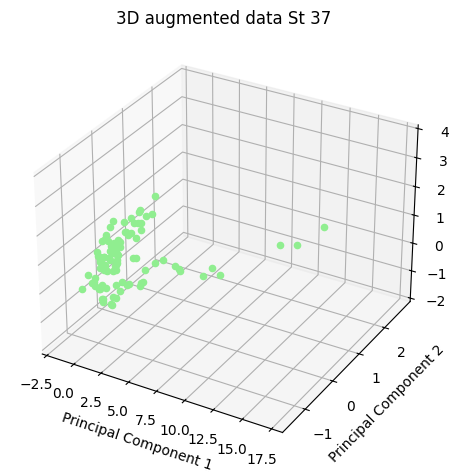

In [20]:
x = pca_augmented_rows[:, 0]
y = pca_augmented_rows[:, 1]
z = pca_augmented_rows[:, 2]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for i in range(len(x)):
        ax.scatter(x[i], y[i], z[i], c='lightgreen', marker='o')

ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('3D augmented data St 37')

ax.set_xlim(-2.5, 18)
#ax.set_ylim(-2, 4)
ax.set_zlim(-2, 4)

plt.tight_layout()
plt.savefig('GAN_Aug_ONLYSt37.png', format='png')

plt.show()

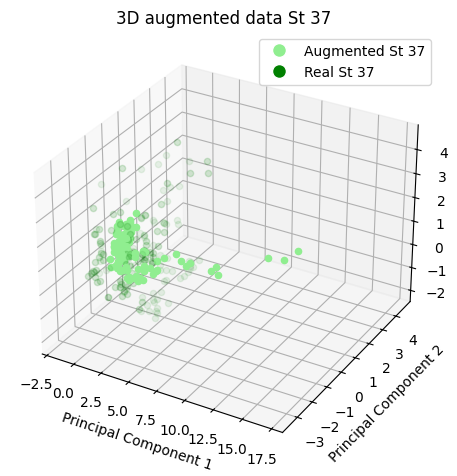

In [21]:
st37_samples = dfs_by_steeltype[1]
scaled_St37_rows = scaler.fit_transform(st37_samples)
pca_St37_rows = pca.fit_transform(scaled_St37_rows)

x_st37 = pca_St37_rows[:, 0]
y_st37 = pca_St37_rows[:, 1]
z_st37 = pca_St37_rows[:, 2]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for i in range(len(x)):
        ax.scatter(x[i], y[i], z[i], c='lightgreen', marker='o', label="Augmented St 37")

for i in range(len(x_st37)):
        ax.scatter(x_st37[i], y_st37[i], z_st37[i], c='g', marker='o', alpha=0.08, label="Real St 37")

legend_elements = []
legend_elements.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="lightgreen", markersize=10, label="Augmented St 37"))
legend_elements.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="g", markersize=10, label="Real St 37"))
plt.legend(handles=legend_elements, loc="upper right")

ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('3D augmented data St 37')

ax.set_xlim(-2.5, 18)
#ax.set_ylim(-2, 10)
#ax.set_zlim(-4, 8)

plt.tight_layout()
plt.savefig('GAN_Aug_St37.jpg', format='png')

plt.show()

[array([9.83617  , 1.5940996, 0.2233649], dtype=float32), array([11.095543  ,  1.727043  ,  0.22388877], dtype=float32), array([11.1036415 ,  2.7296212 ,  0.03097831], dtype=float32)]
[22, 44, 95]


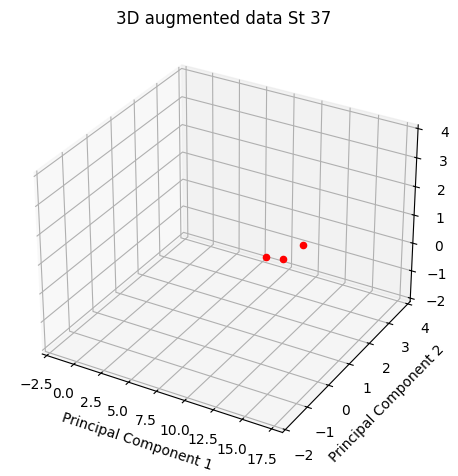

In [22]:
outliers = []
index_outliers = []
for index in range(len(pca_augmented_rows)):
    if pca_augmented_rows[index][0] > 8:
        outliers.append(pca_augmented_rows[index])
        index_outliers.append(index)
print(outliers)
print(index_outliers)



fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for outlier in outliers:
    ax.scatter(outlier[0], outlier[1], outlier[2], c='r', marker='o')
    



ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('3D augmented data St 37')

ax.set_xlim(-2.5, 18)
ax.set_ylim(-2, 4)
ax.set_zlim(-2, 4)


plt.tight_layout()
plt.savefig('Outliers_Aug_St37.jpg', format='png')

plt.show()

Create Ranges for each element

In [23]:
df = pd.DataFrame(augmented_data_St37, columns=['C', 'Si', 'Mn', "P", "S", "Cr", "Ni", "Al", "Cu"])

#Ranges
column_range_C = df["C"].min(), df["C"].max()
column_range_Si = df["Si"].min(), df["Si"].max()
column_range_Mn = df["Mn"].min(), df["Mn"].max()
column_range_P = df["P"].min(), df["P"].max()
column_range_S = df["S"].min(), df["S"].max()
column_range_Cr = df["Cr"].min(), df["Cr"].max()
column_range_Ni = df["Ni"].min(), df["Ni"].max()
column_range_Al = df["Al"].min(), df["Al"].max()
column_range_Cu = df["Cu"].min(), df["Cu"].max()

print("Range of C: ", column_range_C)
print("Range of Si: ", column_range_Si)
print("Range of Mn: ", column_range_Mn)
print("Range of P: ", column_range_P)
print("Range of S: ", column_range_S)
print("Range of Cr: ", column_range_Cr)
print("Range of Ni: ", column_range_Ni)
print("Range of Al: ", column_range_Al)
print("Range of Cu: ", column_range_Cu)


Range of C:  (0.0005072948, 0.03505194)
Range of Si:  (4.475974e-06, 0.0039071203)
Range of Mn:  (0.31050995, 0.39836895)
Range of P:  (8.85744e-05, 0.011275458)
Range of S:  (9.092107e-08, 0.00057515246)
Range of Cr:  (4.0358533e-08, 0.0004849198)
Range of Ni:  (1.0348314e-06, 0.002048513)
Range of Al:  (7.459761e-06, 0.003896401)
Range of Cu:  (0.103196874, 0.262508)


Plot Distributions

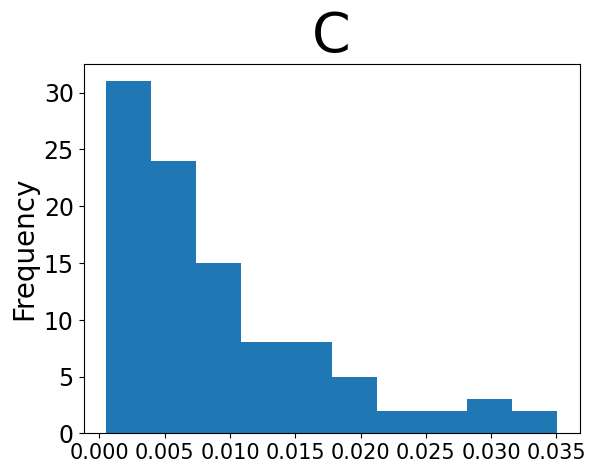

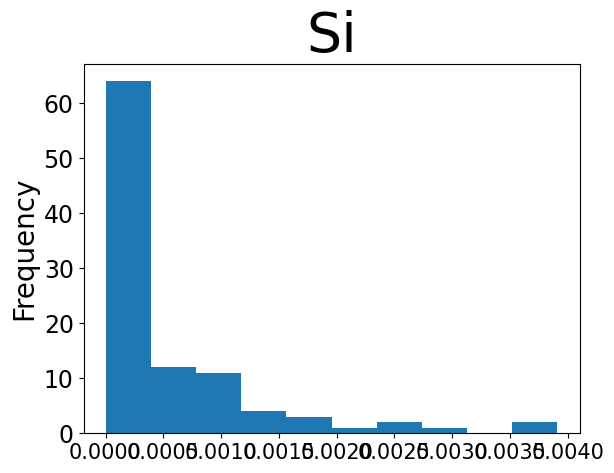

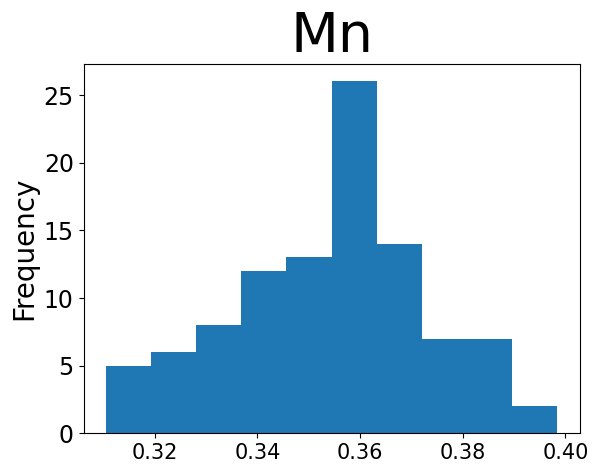

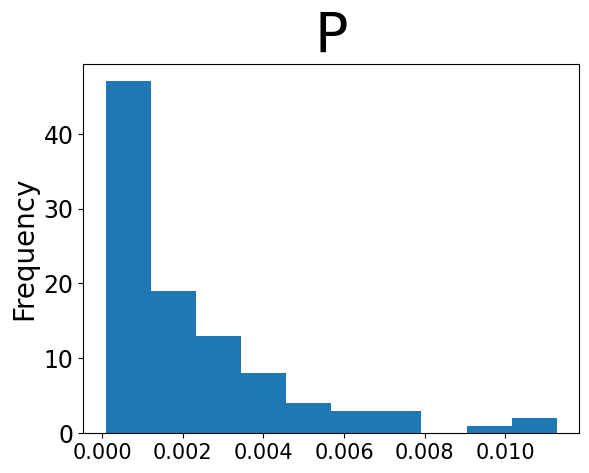

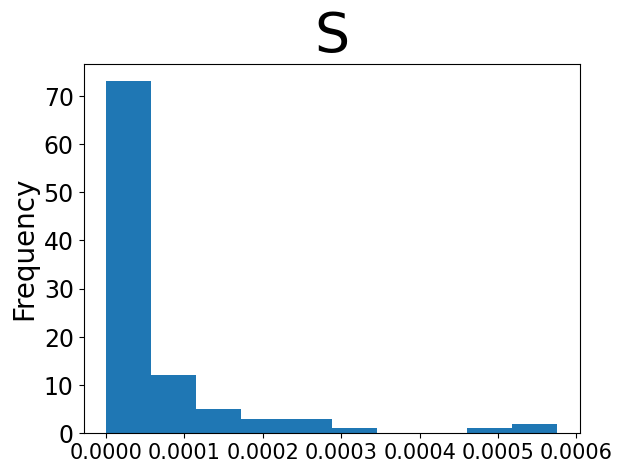

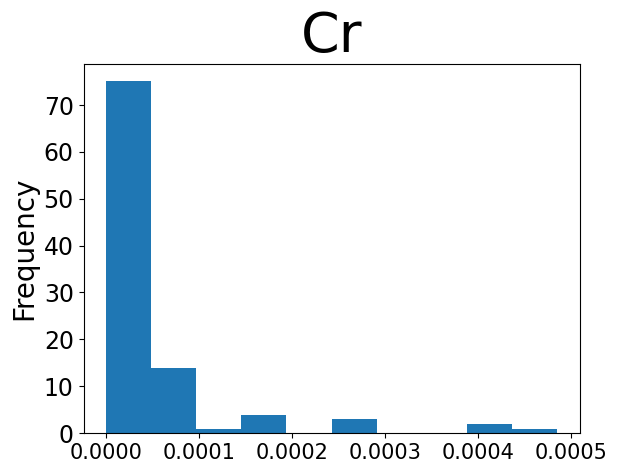

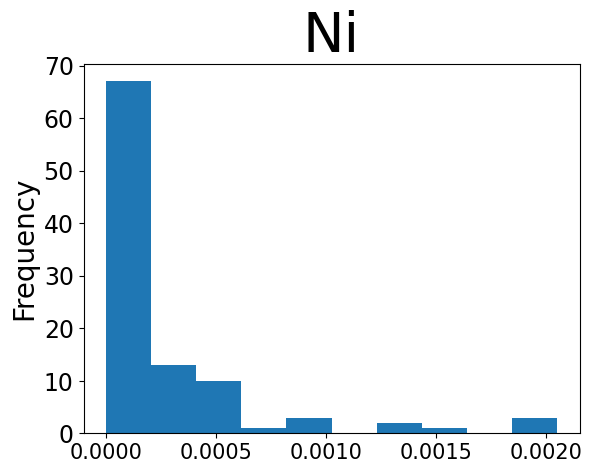

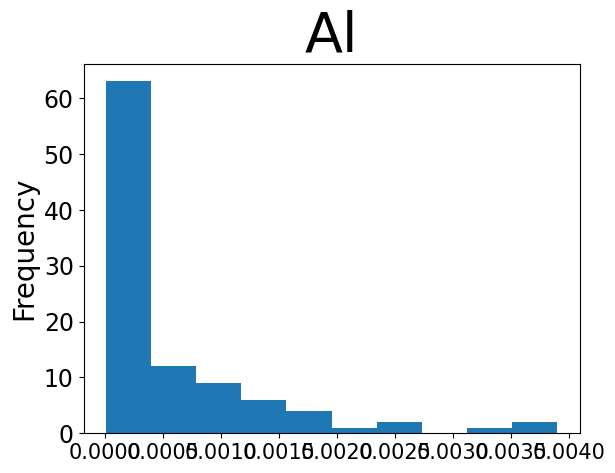

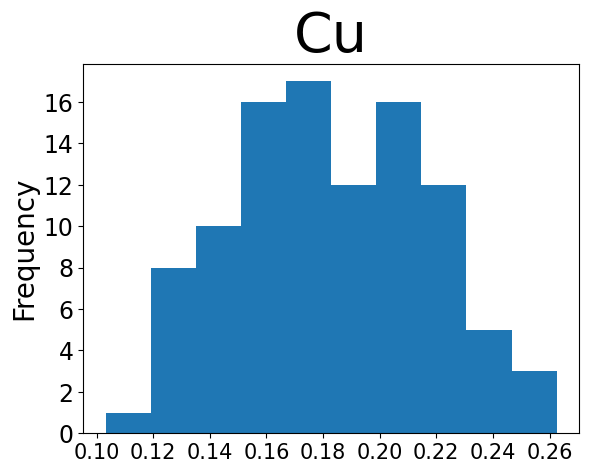

In [24]:
for col in df.columns:  # Loop through columns (excluding the first)
    df[col].plot.hist()
    plt.title(col, fontsize=40)  # Set title as element name
    plt.ylabel("Frequency", fontsize=20)
    plt.xticks(fontsize=15)  # Adjust x-axis tick label font size
    plt.yticks(fontsize=17)
    plt.savefig(f"Distribution_{col}.png", format='png')
    plt.show()
    plt.close()

<br>

## 7. Evaluate the quality of data with Steel Classification Neural Network

In [25]:
import keras

steel_classification_NN = keras.models.load_model("Steel_classifiying_Neural_Network.keras")

C:\Users\jonat\PycharmProjects\GAN_BA\venv\lib\site-packages\keras\src\saving\saving_lib.py:418: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 12 variables whereas the saved optimizer has 22 variables. 
  trackable.load_own_variables(weights_store.get(inner_path))


In [26]:
predictions_aug_St37 = steel_classification_NN.predict(augmented_data_St37)
rev_classes_dict = {0: "St 48", 1 : "St 37", 2 : "St Si", 3 : "St 48-TH", 4 : "Puddelstahl"}


misclassified = []
index = 0
for pred in predictions_aug_St37.argmax(axis=-1):
    print(rev_classes_dict[pred])
    if rev_classes_dict[pred] != "St 37":
        misclassified.append(index)
    index += 1

misclassified


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step 
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37


[]

In [27]:
print("Puddle steel classifications: ", len(misclassified))
print("St 37 classifications: ", 100 - len(misclassified))
for index in misclassified:
    print(predictions_aug_St37.max(axis=-1)[63])

Puddle steel classifications:  0
St 37 classifications:  100


<br>

In [28]:
column_range_C = dfs_by_steeltype[1]["C"].min(), dfs_by_steeltype[1]["C"].max()
column_range_Si = dfs_by_steeltype[1]["Si"].min(), dfs_by_steeltype[1]["Si"].max()
column_range_Mn = dfs_by_steeltype[1]["Mn"].min(), dfs_by_steeltype[1]["Mn"].max()
column_range_P = dfs_by_steeltype[1]["P"].min(), dfs_by_steeltype[1]["P"].max()
column_range_S = dfs_by_steeltype[1]["S"].min(), dfs_by_steeltype[1]["S"].max()
column_range_Cr = dfs_by_steeltype[1]["Cr"].min(), dfs_by_steeltype[1]["Cr"].max()
column_range_Ni = dfs_by_steeltype[1]["Ni"].min(), dfs_by_steeltype[1]["Ni"].max()
column_range_Al = dfs_by_steeltype[1]["Al"].min(), dfs_by_steeltype[1]["Al"].max()
column_range_Cu = dfs_by_steeltype[1]["Cu"].min(), dfs_by_steeltype[1]["Cu"].max()

print("Range of C: ", column_range_C)
print("Range of Si: ", column_range_Si)
print("Range of Mn: ", column_range_Mn)
print("Range of P: ", column_range_P)
print("Range of S: ", column_range_S)
print("Range of Cr: ", column_range_Cr)
print("Range of Ni: ", column_range_Ni)
print("Range of Al: ", column_range_Al)
print("Range of Cu: ", column_range_Cu)

Range of C:  (0.0164, 0.269666666666667)
Range of Si:  (0.001, 0.29)
Range of Mn:  (0.28, 0.682)
Range of P:  (0.0035, 0.0731)
Range of S:  (0.0111666666666667, 0.1)
Range of Cr:  (0.005, 0.109)
Range of Ni:  (0.01485, 0.107166666666667)
Range of Al:  (0.0007, 0.0510666666666667)
Range of Cu:  (0.0069333333333333, 0.285111111111111)


<br>

## 8. Evaluate the quality of data with Steel Classification XGBoost Classifier

In [29]:
steel_classifification_XGBoost = xgb.Booster()
steel_classifification_XGBoost.load_model("Steel_classifying_XGBoost.json")

In [30]:
df = pd.DataFrame(augmented_data_St37, columns=["C", "Si", "Mn", "P", "S", "Cr", "Ni", "Al", "Cu"])
predictions_XGBoost = steel_classifification_XGBoost.predict(xgb.DMatrix(df))

for pred in predictions_XGBoost:
    print(rev_classes_dict[pred])

St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
St 37
